# Model Comparison

The below setup is the same as notebook 02, the cleaning and data split are the same too. All models are compared on the same data, in order to make sure the comparison between models is fair and any difference in results come from the model itself.

In [99]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay

In [100]:
df = pd.read_excel("../data/default of credit card clients.xls", header=1)
df.shape

(30000, 25)

In [101]:
df = df.drop(columns="ID")
df = df.drop_duplicates()
df.shape

(29965, 24)

In [102]:
df["EDUCATION"] = df["EDUCATION"].replace({0 :4, 5 :4, 6 :4})
print(df["EDUCATION"].value_counts().sort_index())

df["MARRIAGE"] = df["MARRIAGE"].replace({0 :3})
print(df["MARRIAGE"].value_counts().sort_index())

EDUCATION
1    10563
2    14019
3     4915
4      468
Name: count, dtype: int64
MARRIAGE
1    13643
2    15945
3      377
Name: count, dtype: int64


In [103]:
df = df.rename(columns={"default payment next month": "default"})

In [104]:
X = df.drop(columns="default")
y = df["default"]
print(X.shape, y.shape)

(29965, 23) (29965,)


In [105]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42
)

In [106]:
print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_val.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(17979, 23) (5993, 23) (5993, 23)
default
0    0.778742
1    0.221258
Name: proportion, dtype: float64
default
0    0.778742
1    0.221258
Name: proportion, dtype: float64
default
0    0.778742
1    0.221258
Name: proportion, dtype: float64


In [107]:
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [col for col in X.columns if col not in cat_cols]
print(len(cat_cols), len(num_cols))

3 20


In [108]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [109]:
def evaluate(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    cost = 5 * fn + 1 * fp
    return {
        "Accuracy": accuracy_score(y, y_pred),
        "Precision": precision_score(y, y_pred, zero_division = 0),
        "Recall": recall_score(y, y_pred),
        "F1": f1_score(y, y_pred, zero_division = 0),
        "PR-AUC": average_precision_score(y, y_proba),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Cost": cost
    }


This evaluation function returns all the metrics from accuracy to TP, along with cost, for any given model. I used this to make sure every model is scored the same way on validation set.

In [110]:
baseline = Pipeline([
    ("prep", preprocessor),
    ("model", DummyClassifier(strategy = "most_frequent")),
])

baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

In [111]:
evaluate(baseline, X_val, y_val)

{'Accuracy': 0.7787418655097614,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1': 0.0,
 'PR-AUC': 0.22125813449023862,
 'TN': np.int64(4667),
 'FP': np.int64(0),
 'FN': np.int64(1326),
 'TP': np.int64(0),
 'Cost': np.int64(6630)}

These results are the exact same as notebook 02's baseline results, just to confirm the evaluate function works correctly, with both costs being 6630.

In [112]:
log_reg = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(class_weight = "balanced", max_iter = 1000)),
])

log_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

In [113]:
evaluate(log_reg, X_val, y_val)

{'Accuracy': 0.6911396629400968,
 'Precision': 0.38276016078606523,
 'Recall': 0.6463046757164405,
 'F1': 0.48078541374474054,
 'PR-AUC': 0.5027566294971519,
 'TN': np.int64(3285),
 'FP': np.int64(1382),
 'FN': np.int64(469),
 'TP': np.int64(857),
 'Cost': np.int64(3727)}

Above, I used a Logistic Regression model and set the class weight to balanced, so that in this model not catching a defaulter is more costly, which pushes the model to try catch defaulters. I set max_iter to 1000 just to give it enough iterations to finish training. Compared to the baseline, it's accuracy dropped 0.78 to 0.69, recall rose 0 to 0.65, and cost went down from 6630 to 3727. PR-AUC rose from 0.22 to 0.5. To add context to those figures, this model now catches about 65% of all defaulters. Even though the accuracy is lower for this model, it's still a better model, because it actually catches a large amount of true defaulters compared to the lazy model, and it reduces the cost by almost a half. The higher PR-AUC means this model is better at keeping a higher precision while still keeping its recall. This suggests this model performs better than the baseline lazy model.

In [114]:
tree = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(class_weight = "balanced", max_depth = 5, random_state = 42))
])

tree.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

In [115]:
evaluate(tree, X_val, y_val)

{'Accuracy': 0.7208409811446688,
 'Precision': 0.4181217555450684,
 'Recall': 0.6681749622926093,
 'F1': 0.5143686502177068,
 'PR-AUC': 0.51507261572076,
 'TN': np.int64(3434),
 'FP': np.int64(1233),
 'FN': np.int64(440),
 'TP': np.int64(886),
 'Cost': np.int64(3433)}

Above is the decision tree model. Its class weight is balanced as missing a defaulter costs more and max depth set to 5 to avoid overfitting, as the model would memorise noise in the training data and look great on it, but poor on the validation. The depth set to 5 keeps it simple enough to generalise. Random state = 42 so that the tree will always give the same result everytime its run. Comparing it then to the logistic regression model, it performs better, but not by much. The cost is lower at 3433, and it catches 29 more defaulters.

In [116]:
forest = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(n_estimators = 200, max_depth = 10, class_weight = "balanced", random_state = 42, n_jobs = -1))
])

forest.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

In [117]:
evaluate(forest, X_val, y_val)

{'Accuracy': 0.779576172200901,
 'Precision': 0.501609787508049,
 'Recall': 0.5874811463046757,
 'F1': 0.5411601250434178,
 'PR-AUC': 0.559776721835374,
 'TN': np.int64(3893),
 'FP': np.int64(774),
 'FN': np.int64(547),
 'TP': np.int64(779),
 'Cost': np.int64(3509)}

This is the random forest model. I used 200 trees as each tree is trained on slightly different data and each makes its own mistakes, that get averaged out across a high number of trees. The class weights are balanced to make not catching a defaulter more costly. The depth was set to 10 so that it makes sure we can generalise it, like the last model. The depth is higher due to more decision trees, as the mistakes get averaged out so that the trees can be big without the forest overfitting. And again, random_state = 42 to keep reproducibility. This model has the best PR-AUC and F1 but a higher cost, which is because it missed more defaulters (547 missed vs 440), which is more costly than flagging a good customer. That's why the cost is higher, and I'll use threshold tuning to fix it later on.

In [118]:
results = pd.DataFrame({
    "Baseline": evaluate(baseline, X_val, y_val),
    "Logistic Regression": evaluate(log_reg, X_val, y_val),
    "Tree": evaluate(tree, X_val, y_val),
    "Forest": evaluate(forest, X_val, y_val)    
})

In [119]:
results

,Baseline,Logistic Regression,Tree,Forest
Accuracy,0.778742,0.691140,0.720841,0.779576
Precision,0.000000,0.382760,0.418122,0.501610
Recall,0.000000,0.646305,0.668175,0.587481
F1,0.000000,0.480785,0.514369,0.541160
PR-AUC,0.221258,0.502757,0.515073,0.559777
TN,4667.000000,3285.000000,3434.000000,3893.000000
FP,0.000000,1382.000000,1233.000000,774.000000
FN,1326.000000,469.000000,440.000000,547.000000
TP,0.000000,857.000000,886.000000,779.000000
Cost,6630.000000,3727.000000,3433.000000,3509.000000


## Results Table

In [120]:
results.T.round(3)

,Accuracy,Precision,Recall,F1,PR-AUC,TN,FP,FN,TP,Cost
Baseline,0.779,0.000,0.000,0.000,0.221,4667.0,0.0,1326.0,0.0,6630.0
Logistic Regression,0.691,0.383,0.646,0.481,0.503,3285.0,1382.0,469.0,857.0,3727.0
Tree,0.721,0.418,0.668,0.514,0.515,3434.0,1233.0,440.0,886.0,3433.0
Forest,0.780,0.502,0.587,0.541,0.560,3893.0,774.0,547.0,779.0,3509.0


The above table shows all results compared against each other, being the baseline and the 3 models I used. The model with the lowest cost, is the Tree at 3433, and the model with the best PR-AUC is the forest with 0.560 but it missed more defaulters(547). Missing a defaulter is more costly than flagging a non defaulter, which increases the cost of the model. Tree also has the highest recall, being 0.668, meaning it catches the biggest proportion of the total defaulters. All 3 of these models clearly beat the baseline.

In [121]:
forest_proba = forest.predict_proba(X_val)[:, 1]

In [122]:
thresholds = np.arange(0.05, 1, 0.05)

In [123]:
costs = []
for t in thresholds:
    pred = (forest_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    costs.append(5 * fn + 1 * fp)

costs

[np.int64(4667),
 np.int64(4651),
 np.int64(4551),
 np.int64(4353),
 np.int64(3751),
 np.int64(3386),
 np.int64(3318),
 np.int64(3356),
 np.int64(3419),
 np.int64(3509),
 np.int64(3653),
 np.int64(3827),
 np.int64(4172),
 np.int64(4375),
 np.int64(4645),
 np.int64(5141),
 np.int64(5611),
 np.int64(6144),
 np.int64(6615)]

In [124]:
best_t = thresholds[np.argmin(costs)]
best_t

np.float64(0.35000000000000003)

In [125]:
costs[np.argmin(costs)]

np.int64(3318)

I used threshold tuning on the forest model to see could I get a better threshold to reduce cost. Before, it was set to 0.5, but if a customer had a 0.4 probability of defaulting say, they would not get flagged as a defaulter. If they defaulted and were missed by the model, it would cost 5x as much. If they were flagged and didn't default, it would not cost as much as not picking them up. So from this, we try to find the best threshold. I did this by making a loop, testing thresholds from 0.05 to 0.95, in steps of 0.05, on the validation set, so that the test set stays untouched for my final evaluation. This way, I was able to see the lowest cost from those thresholds. As a result, I got 0.35, which had lowered the cost from 3509 to 3318, the new lowest cost for all models so far(threshold yet to be applied to others!). This optimal threshold has now saved more cost than the default 0.5, and I plan to apply this to the other models too to make things fair for comparison.

# Tuning Tree and Logistic Regression next

In [126]:
def tune_thresholding(model, X, y):
    proba = model.predict_proba(X)[:, 1]
    costs = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        costs.append(5 * fn + 1 * fp)
    best = np.argmin(costs)
    return thresholds[best], costs[best]

In [127]:
print("Logistic Regression:", tune_thresholding(log_reg, X_val, y_val))
print("Tree:", tune_thresholding(tree, X_val, y_val))
print("Forest:", tune_thresholding(forest, X_val, y_val))

Logistic Regression: (np.float64(0.5), np.int64(3727))
Tree: (np.float64(0.4), np.int64(3413))
Forest: (np.float64(0.35000000000000003), np.int64(3318))


That was the tuning applied to all models. I created a function to apply the thresholding to all models to keep things fair, using the same tuning for each model. The results from the 3 models show the forest is still the cheapest so far with the cost being the lowest at 3318. The Log Reg model didn't change, with a threshold still at 0.5, mainly because the class weight = balanced had already shifted the model in the right direction. The tree improved, but barely (3433 to 3413), with a threshold at 0.4. This would be because the depth of 5 only gives a limited number of probabilities so moving the threshold won't change a whole lot. However, the threshold was chosen and the cost was measured on the same validation set, so the cheapest result may be too optimistic, so the real test will be applying the threshold to the test set at the end

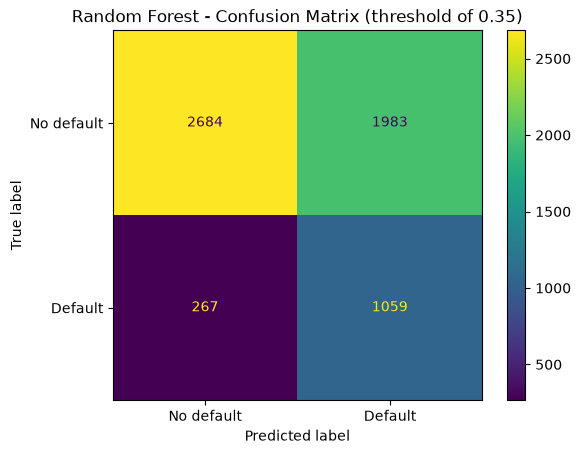

In [129]:
best_pred = (forest_proba >= best_t).astype(int)
ConfusionMatrixDisplay.from_predictions(y_val, best_pred, display_labels = ["No default", "Default"])
plt.title("Random Forest - Confusion Matrix (threshold of 0.35)")
plt.show()